# Описание задания к работе.

1. Исходные данные представляют собой `CSV` файл с двумя столбцами
2. Реализовать чтение данных из файла
3. Вывести статистическую информацию о используемых данных (количество, `min`, `max`, среднее) по каждому из столбцов
4. Используя библиотеку `Matplotlib` вывести изображение исходных точек
5. Реализовать алгоритм метода наименьших квадратов и вычислить параметры регрессионной прямой.
6. Используя библиотеку `Matplotlib` и полученное в п.3 изображение отрисовать на изображении другим цветом полученную прямую
7. Используя полученное в п.5 изображение, отрисовать и заштриховать квадраты ошибок 

**Общие замечания:** программа должна позволять работать с другими входными файлами, программа должна позволять выбрать какой из входных столбцов выбрать в качестве `Х` а какой в качестве `У`(в случае если столбцов больше 2), по завершению программы должны одновременно видны все 3 изображения (п.3, п.5, п.6)


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

### П.2

In [2]:
data = pd.read_csv('lab1_DS.csv')

In [3]:
data

,YearsExperience,Salary
0,1.1,39343
1,1.3,46205
2,1.5,37731
3,2.0,43525
4,2.2,39891
5,2.9,56642
6,3.0,60150
7,3.2,54445
8,3.2,64445
9,3.7,57189


### П.3

In [4]:
x_column = data.columns[0] # выбрать нужный столбец
y_column = data.columns[1] # выбрать нужный столбец

X = data[x_column].values
Y = data[y_column].values

In [5]:
print('info about X column:')
print(f'count: {len(X)}')
print(f'max: {X.max()}')
print(f'min: {X.min()}')
print(f'mean: {X.mean():.2f}')

info about X column:
count: 35
max: 13.5
min: 1.1
mean: 6.31


In [6]:
print('info about Y column:')
print(f'count: {len(Y)}')
print(f'max: {Y.max()}')
print(f'min: {Y.min()}')
print(f'mean: {Y.mean():.4f}')

info about Y column:
count: 35
max: 139465
min: 37731
mean: 83945.6000


### П.4

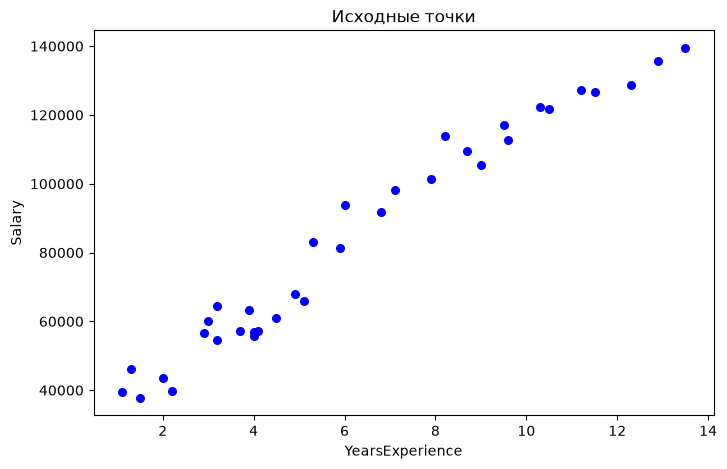

In [17]:
fig1, ax1 = plt.subplots(figsize=(8, 5))
ax1.scatter(X, Y, color='blue', s=30)
ax1.set_xlabel(x_column)
ax1.set_ylabel(y_column)
ax1.set_title('Исходные точки')
plt.show()

### П.5

In [8]:
X_b = np.c_[np.ones((len(X), 1)), X]

In [9]:
weights = np.linalg.inv(X_b.T.dot(X_b)).dot(X_b.T).dot(Y)
intercept, slope = weights[0], weights[1]
print(f'Сдвиг: {intercept}, Наклон: {slope}')

Сдвиг: 28859.52619453148, Наклон: 8731.941047062497


### П.6

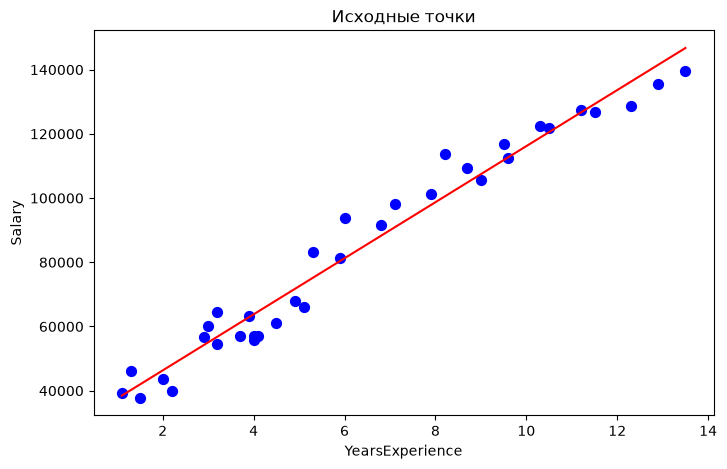

In [10]:
fig1, ax1 = plt.subplots(figsize=(8, 5))
ax1.scatter(X, Y, color='blue', s=50)
ax1.set_xlabel(x_column)
ax1.set_ylabel(y_column)
ax1.set_title('Исходные точки')

X_min_max = np.array([X.min(), X.max()])
y = slope * X_min_max + intercept
ax1.plot(X_min_max, y, color="red")

plt.show()

### П.7

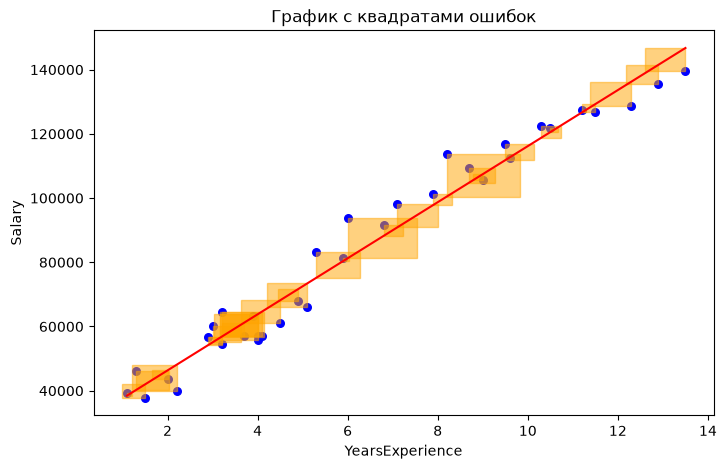

In [16]:
fig1, ax1 = plt.subplots(figsize=(8, 5))
ax1.scatter(X, Y, color='blue', s=30)
ax1.set_xlabel(x_column)
ax1.set_ylabel(y_column)
ax1.set_title('График с квадратами ошибок')

X_min_max = np.array([X.min(), X.max()])
y = slope * X_min_max + intercept
ax1.plot(X_min_max, y, color="red")

y_pred = slope * X + intercept

x_scale = (X.max() - X.min()) / (Y.max() - Y.min())

for i in range(len(X)):
    err = Y[i] - y_pred[i]
    x_err = err * x_scale
    x_square = [X[i], X[i] + x_err, X[i] + x_err, X[i]]
    y_square = [y_pred[i], y_pred[i], Y[i], Y[i]]
    ax1.fill(x_square, y_square, color="orange", alpha = 0.5)

plt.show()

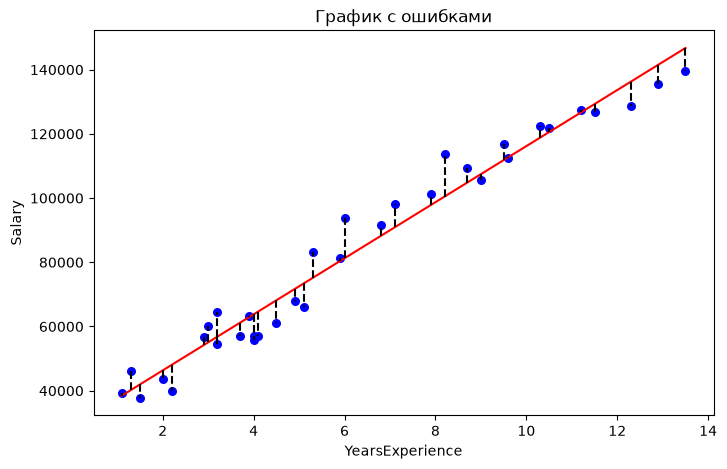

In [12]:
fig1, ax1 = plt.subplots(figsize=(8, 5))
ax1.scatter(X, Y, color='blue', s=30)
ax1.set_xlabel(x_column)
ax1.set_ylabel(y_column)
ax1.set_title('График с ошибками')

X_min_max = np.array([X.min(), X.max()])
y = slope * X_min_max + intercept
ax1.plot(X_min_max, y, color="red")

y_pred = slope * X + intercept

for i in range(len(X)):
    ax1.plot([X[i], X[i]], [y_pred[i], Y[i]], color = 'black', linestyle='--')

plt.show()